In [1]:
import uts
import utsviz # hand for vizualization, but not required for uts itself
%matplotlib inline

`uts` makes working with uniformly sampled time signals easier. It basically is a wrapper around numpy, but it has its own objects that are aware of time, channels, and epochs. You can also save and load such objects, vizualize them (with additional `utsviz` library, and enables you to work with signals that are larger than RAM memory. 

## uniform time signal

UniformTimeSeries are the simplest objects. Just one signal. Lets create one from scratch.

In [26]:
s = uts.UniformTimeSeries([1.,2.,3.,4.,5.,6.,7.,8.,9.,10.], fs=5.) # fs means sampling rate, need to be floating point
print(s)

<UniformTimeSeries: 2.000 seconds, 10 times>


The actual samples are to be found in the samples attribute, which can be indexed as a numpy object to get a numpy object.

The most important aspect in uts to get first is that there are two ways to index time in object. Use *integers* to indicate sample *numbers*, and *floats* to indicate time. This is both very handy and dangerous if you do not know this.

In [27]:
s[:2] # indexing by sample number

<UniformTimeSeries: 0.400 seconds, 2 times>

In [28]:
s[:0.4] # indexing by time (in seconds)

<UniformTimeSeries: 0.400 seconds, 2 times>

If you want the samples in a numpy array, access the samples attribute, which can be indexed like a *numpy* array:

In [29]:
s.samples[:]

array([ 1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10.])

In [30]:
s[0.4:].samples[:]

array([ 3.,  4.,  5.,  6.,  7.,  8.,  9., 10.])

In [31]:
s[0.4:0.8].samples[:]

array([3., 4.])

UniformTimeSeries have a lot of useful methods and attributes, try them by using tab completion below:

In [ ]:
s.

just to give some examples:

In [32]:
s.samplingtimes() # a sampling time is defined as the *center* of the duration of taking the sample.

array([0.1, 0.3, 0.5, 0.7, 0.9, 1.1, 1.3, 1.5, 1.7, 1.9])

In [33]:
s.samplingboundarytimes()

array([0. , 0.2, 0.4, 0.6, 0.8, 1. , 1.2, 1.4, 1.6, 1.8, 2. ])

In [35]:
for chunk in s.iter_frames(3):
    print(chunk)

<UniformTimeSeries: 0.600 seconds, 3 times>
<UniformTimeSeries: 0.600 seconds, 3 times>
<UniformTimeSeries: 0.600 seconds, 3 times>
<UniformTimeSeries: 0.200 seconds, 1 times>


In [36]:
s = uts.UniformTimeSeries([1.,2.,3.,4.,5.,6.,7.,8.,9.,10.], fs=5., startdatetime="2021-04-13T12:05:03.0")
s.datetime_to_index("2021-04-13T12:05:03.8")

4

we can quickly vizualize with utsviz, which is wrapped around matplotlib

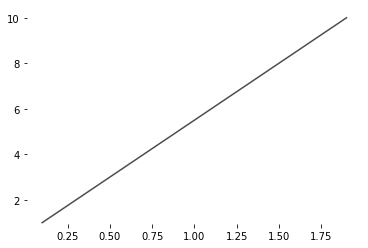

In [38]:
a = utsviz.plot(s)

Another advantage of uts is that it has many functions that operate on time signals, and these functions are time aware. For example:

<UniformTimeSeries: 2.000 seconds, 10 times>


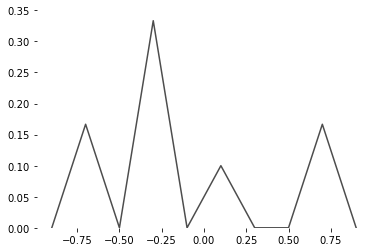

In [58]:
s1 = uts.UniformTimeSeries([0.,0.,0.5,0.,1.,0.,0.3,0.,0.,0.5, 0.,0.2], fs=5.)
s2 = uts.UniformTimeSeries([0.,1.,0.], fs=5.)
cc = uts.crosscorrelatetime(s1,s2, normalized=False)
print(cc)
a = utsviz.plot(cc)

In [59]:
s1.index_to_time(uts.argmax(cc))

0.7

## multichannel uniform time signal

If you have multiple channels in parallel, uts handles that as well. Let's take a real signal this time, one from an electrophysiology recording of a traveling wave in the avian brain. It is includes as an example in uts. The wave, when visualized in a movies looks like a doughnut/donut, hence its name. 

In [83]:
s = uts.load_doughnutexamplelfp()
print(s)

<MultiChannelUniformTimeSeries: 0.300 seconds, 4202 times, 64 channels>


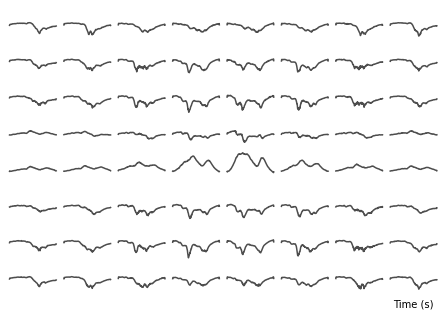

In [63]:
a = utsviz.plot(s)

Note above that these objects may also include info about the geometry of the different channels. In this case the recording sites were organized as a regular matrix, which is used when visualizing things.

In [64]:
s.channelnames # channels have names

array(['electrode_01', 'electrode_02', 'electrode_03', 'electrode_04',
       'electrode_05', 'electrode_06', 'electrode_07', 'electrode_08',
       'electrode_09', 'electrode_10', 'electrode_11', 'electrode_12',
       'electrode_13', 'electrode_14', 'electrode_15', 'electrode_16',
       'electrode_17', 'electrode_18', 'electrode_19', 'electrode_20',
       'electrode_21', 'electrode_22', 'electrode_23', 'electrode_24',
       'electrode_25', 'electrode_26', 'electrode_27', 'electrode_28',
       'electrode_29', 'electrode_30', 'electrode_31', 'electrode_32',
       'electrode_33', 'electrode_34', 'electrode_35', 'electrode_36',
       'electrode_37', 'electrode_38', 'electrode_39', 'electrode_40',
       'electrode_41', 'electrode_42', 'electrode_43', 'electrode_44',
       'electrode_45', 'electrode_46', 'electrode_47', 'electrode_48',
       'electrode_49', 'electrode_50', 'electrode_51', 'electrode_52',
       'electrode_53', 'electrode_54', 'electrode_55', 'electrode_56',
      

You can index channels by name or by index number. In uts the first axis is always time (although in the underlying array this may not be the case), and if channels are present, they are indexed in the second axis.

In [65]:
s[0.1:0.2]

<MultiChannelUniformTimeSeries: 0.100 seconds, 1401 times, 64 channels>

In [66]:
s[:, ['electrode_58', 'electrode_43']]

<MultiChannelUniformTimeSeries: 0.300 seconds, 4202 times, 2 channels>

In [67]:
s[0.1:0.2, ['electrode_58', 'electrode_43']]

<MultiChannelUniformTimeSeries: 0.100 seconds, 1401 times, 2 channels>

In [68]:
s[0.1:0.2, [50,24]]

<MultiChannelUniformTimeSeries: 0.100 seconds, 1401 times, 2 channels>

In [ ]:
s[0.1:0.2, [50,24]].channelnames

Let's look at an interesting function again. Now lets look at the raw recording of the doughnut, and filter it.

In [87]:
s = uts.load_doughnutexampleraw()

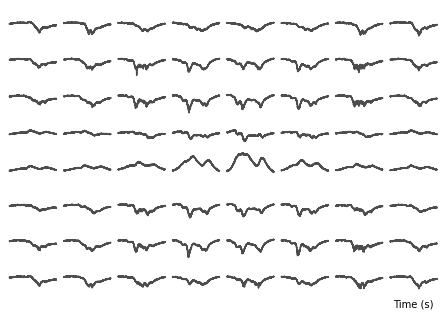

In [88]:
utsviz.plot(s)

In [89]:
sf = uts.lp(s, freq=100, width=10) # lowpass

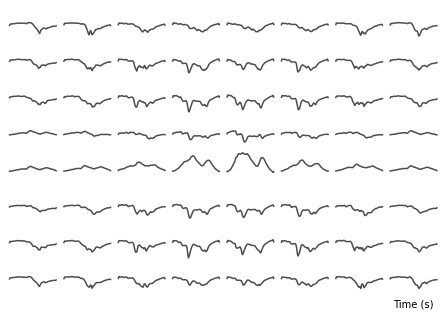

In [90]:
a = utsviz.plot(sf)

In [91]:
sf = uts.hp(s, freq=300, width=100) # highpass

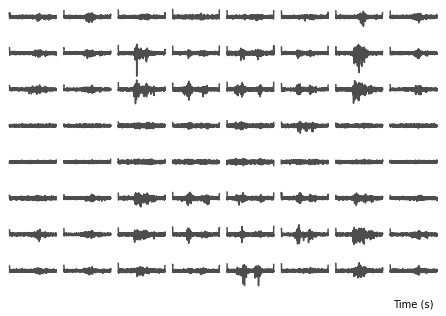

In [92]:
a = utsviz.plot(sf)

We can save signals. The defaults is to use darr format, which is maximally simple and open. https://github.com/gbeckers/Darr . But more complicated formats such as hdf5 are available as well. This can be handy if you want advanced features like compression, or need to have things in one file (darr uses a directory of files).

In [98]:
uts.save('doughnut_actionpotentials', sf, overwrite=True)

<MultiChannelUniformTimeSeries: 0.300 seconds, 4202 times, 64 channels>

In [104]:
sf = uts.open('doughnut_actionpotentials')

When opened from disk, the sample data is not read into memory, allowing you to 'open' very large data objects. They are treated as normal uts objects, so that you can index them, in which case the selected parts are read into memory as a numpy array.

In [107]:
type(sf.samples) # samples are still on disk, so this could be *very* large

uts.core.samplesource.DarrSamples

In [109]:
type(sf[:0.1].samples) # indexing will read them into memory

uts.core.samplesource.NumpyArraySamples

Many functions in uts will try and not read the whole signal into memory, but instead operate on chunks. This saves you many headaches.

## Epoched Uniform Time Signal

to be continued...